# Setup

In [9]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import random as rn
import ast
import sys
sys.path.insert(1, r"C:\Users\Amin\Desktop\trojan\trojan\data engine")
import dataPrep as dp

# Inputs

In [11]:
path = r"C:\Users\Amin\Desktop\trojan\trojan\Numbeo\Quality of Life\Climate Index_PATTERNS_DF.csv"

df   = pd.read_csv(path)
df   = df.drop("Unnamed: 0", axis = 1)

indexName  = path.split("\\")[-1].split(".")[0].split("_")[0]
country1   = rn.choice(list(set(df["Pattern Country"])))
country2   = rn.choice(list(set(df["Match Country"])))
patternLen = rn.choice(list(set(df["Pattern Length"]))) #rn.choice([8, 9, 10])
corrScore  = 0.9

# Crunching

In [12]:
c1df = dp.C1DF(df, country1, patternLen, corrScore)
c1df.head()

,Pattern Country,Match Country,Index,Pattern Values,Pattern Index,Match Values,Match Index,Rank,Score,Correlation Score,Euclidean Score,MAPE Score,DTW Score,CBD Score,Pattern Length
9120,Netherlands,Argentina,Climate Index,"[61.87, 86.93, 87.45, 87.61]","[2017, 2018, 2019, 2020]","[90.67, 98.22, 98.28, 98.28]","[2017, 2018, 2019, 2020]",Platinum,0.0,1.0,34.47,0.21,34.45,0.53,4
9121,Netherlands,Australia,Climate Index,"[61.87, 86.93, 87.45, 87.61]","[2017, 2018, 2019, 2020]","[72.79, 92.41, 93.75, 92.7]","[2017, 2018, 2019, 2020]",Platinum,0.0,1.0,14.66,0.09,14.66,0.51,4
9122,Netherlands,Austria,Climate Index,"[61.87, 86.93, 87.45, 87.61]","[2017, 2018, 2019, 2020]","[62.13, 77.74, 77.74, 77.3]","[2017, 2018, 2019, 2020]",Platinum,0.0,1.0,16.89,0.08,16.89,0.53,4
9124,Netherlands,Belgium,Climate Index,"[61.87, 86.93, 87.45, 87.61]","[2017, 2018, 2019, 2020]","[75.16, 86.14, 86.03, 85.99]","[2017, 2018, 2019, 2020]",Platinum,0.0,1.0,13.49,0.06,13.49,0.51,4
9125,Netherlands,Bosnia And Herzegovina,Climate Index,"[61.87, 86.93, 87.45, 87.61]","[2017, 2018, 2019, 2020]","[78.89, 80.48, 80.48, 80.48]","[2018, 2019, 2020, 2021]",Platinum,0.0,1.0,20.75,0.13,20.75,0.53,4


In [13]:
# Execute this first code block if the C1 dataframe has the passed pattern length `patternLen`
# Then transform it to a vizzable dataframe `dfViz`
if not isinstance(c1df, dict):
    # Pattern Index options
    pattIndex = rn.choice(list(set(c1df["Pattern Index"])))
    print("Pattern Indexes")
    print(list(set(c1df["Pattern Index"])))
    print("Choice:", pattIndex)

    c1df  = c1df[c1df["Pattern Index"] == pattIndex]
    dfViz = dp.patternVsMatchesDF(c1df, country1, patternLen)
else:
    print("Selected pattern length (", patternLen, ") does not apply to selected country (", country1, "). ")

Pattern Indexes
['[2017, 2018, 2019, 2020]', '[2016, 2017, 2018, 2019]']
Choice: [2017, 2018, 2019, 2020]


# Viz

C:\Users\Amin\AppData\Local\Temp\ipykernel_23732\2619908069.py:1: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use("seaborn-darkgrid")


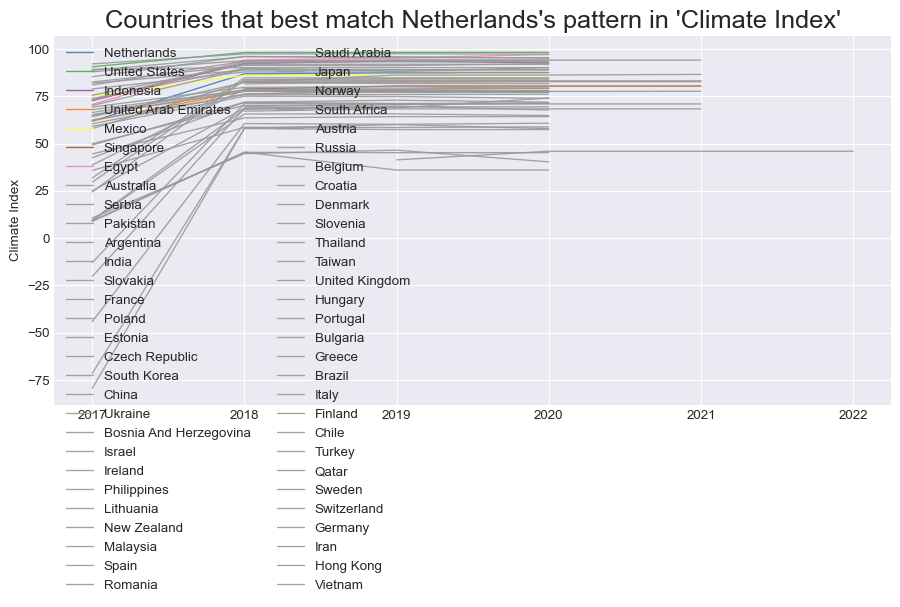

In [14]:
plt.style.use("seaborn-darkgrid")
my_dpi = 96
plt.figure(figsize = (1080 / my_dpi, 480 / my_dpi), dpi = my_dpi)
palette = plt.get_cmap("Set1")
 
num = 0
for column in dfViz.drop("Years", axis = 1):
    num += 1
    plt.plot(dfViz["Years"], dfViz[column], marker = "", color = palette(num), linewidth = 1, alpha = 0.9, label = column)

plt.legend(loc = 2, ncol = 2)
 
plt.title("Countries that best match " + country1 + "'s pattern in '" + indexName + "'", loc = "center", fontsize = 19, fontweight = 0)
#plt.xlabel("Time")
plt.ylabel(indexName) # <<<<<<<<<<

plt.show()